[课程目录](../../README.md#4-按主题学习-notebook) · [环境部署](../../README.md#1-配置-python-环境)

计算 Pauli 算符、理想与含噪声哈密顿量期望值，保留可选云端示例。

本篇可独立从上到下运行，请选择仓库 `.venv` 对应的内核。量子云步骤默认关闭；只有需要访问云端时才将 `RUN_ON_QCLOUD` 改为 `True`，并在启动 Jupyter 前准备好 `APIKEY` 环境变量。

In [1]:
RUN_ON_QCLOUD = False

if RUN_ON_QCLOUD:
    import os
    if not os.environ.get("APIKEY"):
        raise ValueError("请先设置 APIKEY 环境变量，再开启量子云步骤。")


# 哈密顿量

## 0.Pauli算符期望值

In [2]:
import numpy as np
from pyqpanda3.hamiltonian import Hamiltonian, PauliOperator
from pyqpanda3.core import expval_hamiltonian, expval_pauli_operator
from pyqpanda3.core import QProg, H, CNOT, RY, measure, CPUQVM

构造量子态:

$$
|\psi\rangle = |+\rangle = \frac{1}{\sqrt{2}}\left(|0\rangle + |1\rangle \right)
$$

Pauli矩阵 $X$ 的期望值为：

**方法一**：
$$
\langle X \rangle = \langle +|X|+\rangle = \frac{\langle 0| + \langle 1|}{\sqrt{2}} X \frac{|0\rangle + |1\rangle}{\sqrt{2}} = \frac{\langle 0| + \langle 1|}{\sqrt{2}}\frac{|1\rangle + |0\rangle}{\sqrt{2}} = 1
$$

**方法二**：
$$
\langle X \rangle = \lambda_{+}P_{+} + \lambda_{-}P_{-} = 1 \times 1 + (-1) \times 0 = 1
$$

In [3]:
prog1 = QProg()
prog1 << H(0)

┌─┐ 
q_0:  |0>─┤H├ 
          └─┘ 
 c :   / ════

**理论计算**

In [4]:
pauli_op = PauliOperator('X')
pauli_op_expectation = expval_pauli_operator(prog1, pauli_op)
print(f"Theoretical expectation value of X is: {pauli_op_expectation:.6f}")

Theoretical expectation value of X is: 1.000000


**模拟计算**

先进行换基操作，在测量之前添加 $H$ 门

In [5]:
prog1 << H(0) << measure(0, 0)

┌─┐ ┌─┐  ┌─┐ 
q_0:  |0>─┤H├ ┤H├ ─┤M├ 
          └─┘ └─┘  └╥┘ 
 c :   / ═══════════╩═
                     0

In [6]:
qvm = CPUQVM()
shots = 1000
qvm.run(prog1, shots)
result = qvm.result().get_counts()

simulated_expectation = result.get('0', 0) / shots - result.get('1', 0) / shots
print(f"Simulated expectation value of X is: {simulated_expectation:.6f}")

Simulated expectation value of X is: 1.000000


## 1.模拟器理论计算期望值

$$
H = 0.5 I + 0.7 Z_0 - 0.2 Z_1 + 0.6 X_0X_1
$$

In [7]:
# 字典：空字符串表示恒等项，未出现的比特默认作用 I
ham = Hamiltonian({"": 0.5, "Z0": 0.7, "Z1": -0.2, "X0 X1": 0.6})

In [8]:
# 构建态制备线路
prog = QProg()
prog << RY(0, np.pi/3) << CNOT(0, 1)

┌──┐        
q_0:  |0>─┤RY├ ───*── 
          └──┘ ┌──┴─┐ 
q_1:  |0>───── ┤CNOT├ 
               └────┘ 
 c :   / ════════════

In [9]:
# 计算期望值
exp_val = expval_hamiltonian(prog, ham)
print(f"Expectation value: {exp_val:.6f}")

Expectation value: 1.269615


## 2. 噪声模拟器计算期望值

In [10]:
from pyqpanda3.core import NoiseModel, depolarizing_error, GateType

In [11]:
error = depolarizing_error(0.1)

model = NoiseModel()
model.add_quantum_error(error, GateType.CNOT, [0, 1])

In [12]:
prog = QProg()
prog << RY(0, np.pi/3) << CNOT(0, 1)

┌──┐        
q_0:  |0>─┤RY├ ───*── 
          └──┘ ┌──┴─┐ 
q_1:  |0>───── ┤CNOT├ 
               └────┘ 
 c :   / ════════════

**注意**：使用含噪声模拟计算哈密顿量期望值时，需要添加 `measure`

In [13]:
prog << measure(0, 0) << measure(1, 1)

┌──┐         ┌─┐     
q_0:  |0>─┤RY├ ───*── ─┤M├──── 
          └──┘ ┌──┴─┐  └╥┘ ┌─┐ 
q_1:  |0>───── ┤CNOT├ ──╫──┤M├ 
               └────┘   ║  └╥┘ 
 c :   / ═══════════════╩═══╩═
                         0   1

**注意**：当 shots=1 时，函数使用态矢量模拟计算精确期望值。当 shots > 1 时，它使用指定次数的测量进行基于采样的估计。

In [14]:
exp_val = expval_hamiltonian(prog, ham, shots=1000, model=model)
print(f"Expectation value: {exp_val:.6f}")

Expectation value: 1.147000


## 3. 真机计算哈密顿量期望值

In [15]:
import os
from pyqpanda3.hamiltonian import Hamiltonian
from pyqpanda3.qcloud import QCloudOptions, QCloudService, QCloudJob

In [16]:
prog = QProg()
prog << RY(0, np.pi/3) << CNOT(0, 1)

┌──┐        
q_0:  |0>─┤RY├ ───*── 
          └──┘ ┌──┴─┐ 
q_1:  |0>───── ┤CNOT├ 
               └────┘ 
 c :   / ════════════

In [17]:
if RUN_ON_QCLOUD:
    APIKEY = os.getenv('APIKEY')
    service = QCloudService(APIKEY)
else:
    print("量子云步骤未启用：未连接远端、未提交任务。")


量子云步骤未启用：未连接远端、未提交任务。


In [18]:
if RUN_ON_QCLOUD:
    backend = service.backend("WK_C180")
    exp_val = backend.expval_hamiltonian(prog, ham, QCloudOptions())
    print(f"Expectation value: {exp_val:.6f}")
else:
    print("量子云步骤未启用：未连接远端、未提交任务。")


量子云步骤未启用：未连接远端、未提交任务。


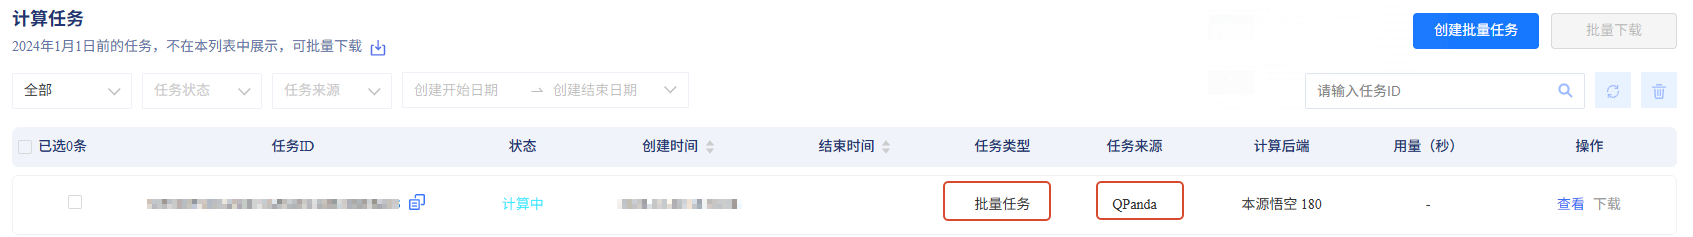

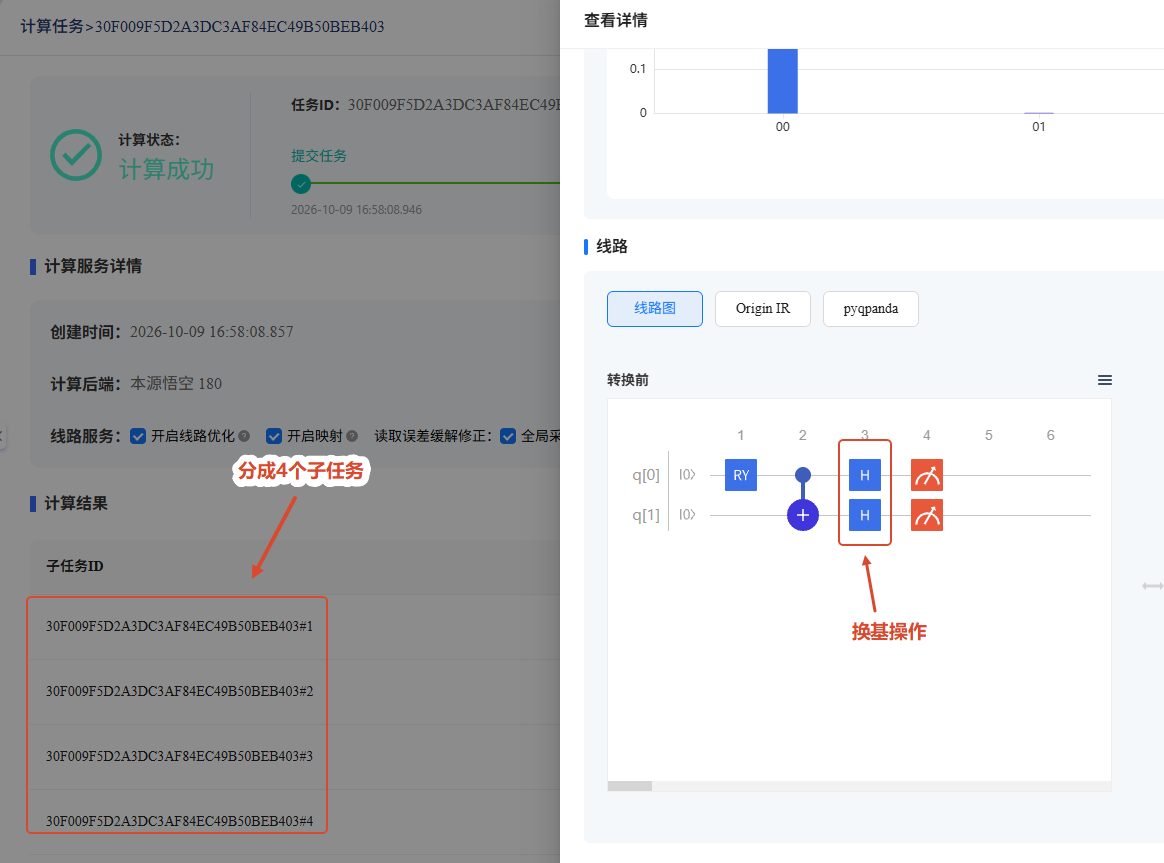

## 图像展示

保留前面的文本结果；下面补充图像形式的线路或本次运行结果。

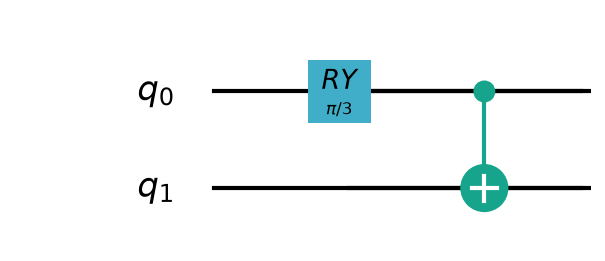

In [19]:
from pathlib import Path
from IPython.display import Image, display
import pyqpanda3.visualization

repo_root = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file())
figure_dir = repo_root / ".tmp/notebook-figures/day2"
figure_dir.mkdir(parents=True, exist_ok=True)
image_path = figure_dir / "01_hamiltonian.png"
prog.draw("pic", filename=str(image_path), with_gate_params=True)
display(Image(filename=str(image_path)))
